# GTA 6 user reviews: EDA and topic modeling

Exploratory analysis of ~51k Metacritic user reviews (PlayStation 5 and Xbox Series X) of GTA 6, followed by an LDA topic model of the English reviews.

The notebook follows CRISP-DM:

| Phase | Section | Question it answers |
|---|---|---|
| 1. Business understanding | [1](#1.-Business-understanding) | What do we want to learn? |
| 2. Data understanding | [2](#2.-Data-understanding) | What is in the data, and can we trust it? |
| 3. Data preparation | [3](#3.-Data-preparation) | What do we keep, and how do we clean it? |
| 4. Modeling | [4](#4.-Modeling) | Which topics do reviewers talk about? |
| 5. Evaluation | [5](#5.-Evaluation) | Are the topics sound and how do they relate to score? |
| 6. Deployment | [6](#6.-Findings,-limitations-and-next-steps) | Findings, limitations, next steps (an analysis, so nothing is deployed) |

Run order matters because cells share state (`df`, `df_en`, `corpus`, ...). Use Restart & Run All.

## 1. Business understanding

Goal: understand how the community received GTA 6 right after launch and what drives positive and negative opinions.

Questions:

1. How are scores distributed, and is the distribution as polarized as it looks?
2. Do PlayStation 5 and Xbox Series X reviewers differ?
3. How do volume and sentiment evolve over the launch days?
4. Which languages are present, and do they differ in score?
5. What themes do English reviewers discuss, and which themes go with high or low scores?

Success criteria: data-quality issues that could bias the answers are identified and handled explicitly, and the topic model is interpretable (no degenerate topics).

## 2. Data understanding

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

SEED = 42
DATA = Path('../data/raw/reviews.csv')
OUT = Path('../data/processed')

sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', 120)

### 2.1 Loading and schema

`reviews.csv` has one row per user review. Columns:

| Column | Meaning |
|---|---|
| `platform` | `playstation-5` or `xbox-series-x` |
| `review_id` | Metacritic profile hash (see 2.2: it identifies the user, not the review) |
| `published_date` | Publication date (day granularity) |
| `score` | User score, integer 0 to 10 |
| `review_text` | Free text, multi-line, multilingual, up to 5,000 characters |

`wc -l` reports ~108k lines because texts contain line breaks; the real row count is 51,385.

In [2]:
df = pd.read_csv(DATA, parse_dates=['published_date'])
df.head()

,platform,review_id,published_date,score,review_text
0,playstation-5,mc-profile-73221238ba69e82808a52ea6f11af92abf38385594313fd8632f82e500efa45f,2026-11-21,6,"I guess it’s just more GTA.\nNo innovations, nothing extraordinary, just more GTA.\nProbably better than GTA V? Hard..."
1,playstation-5,mc-profile-24d933ed22bfa70a548d54edf921231c0883aa626c15ffda32961c62ab458a37,2026-11-21,0,"Me decepciono, tanto tiempo que esperamos para que sea básicamente lo mismo y lleno de bugs, no se pueden hacer cosa..."
2,playstation-5,mc-profile-b4599596d3980783f5b65eee7914d9daa11e3d362bea40f7d80098bda63ba8c4,2026-11-21,0,"13 years to be capped at 30 fps in 2026. Horrible story, first four hours of the story is just boring slop. Just pla..."
3,playstation-5,mc-profile-0ffa47434c1d38d82f989d3adde82423fe0ae72185c32bc2694ecc4328fb35a3,2026-11-21,0,"I'm so disappointed in this woke feminist garbage. I don't want to do choirs for some unworthy women! Also, If you..."
4,playstation-5,mc-profile-cdf748f019c011aac056781d7abb47f6a34166c8c2b657f123d788067c65fdf1,2026-11-21,9,I’m currently on chapter 3 and I’m enjoying the game not just story but the amount of other stuff you can do outside...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51385 entries, 0 to 51384
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   platform        51385 non-null  str           
 1   review_id       51385 non-null  str           
 2   published_date  51385 non-null  datetime64[us]
 3   score           51385 non-null  int64         
 4   review_text     51385 non-null  str           
dtypes: datetime64[us](1), int64(1), str(3)
memory usage: 2.0 MB


In [4]:
df.describe(include='all')

,platform,review_id,published_date,score,review_text
count,51385,51385,51385,51385.000000,51385
unique,2,50229,NaN,NaN,50734
top,playstation-5,mc-profile-9874b830f36cd2f49e36f285cb6dbaa619415cc0709e1c59e3e24d72639f51ed,NaN,NaN,"The game was very mediocre, i wasnt enjoying it much and whished for a much better game i never got"
freq,46317,2,NaN,NaN,12
mean,NaN,NaN,2026-11-21 07:00:41.545198,4.999475,NaN
min,NaN,NaN,2026-11-19 00:00:00,0.000000,NaN
25%,NaN,NaN,2026-11-21 00:00:00,0.000000,NaN
50%,NaN,NaN,2026-11-21 00:00:00,4.000000,NaN
75%,NaN,NaN,2026-11-22 00:00:00,10.000000,NaN
max,NaN,NaN,2026-11-24 00:00:00,10.000000,NaN


### 2.2 Data quality

Checks beyond the obvious full-row duplicates: a repeated `review_id` or a repeated text would double-count opinions in every later chart and in the topic model.

In [5]:
text_key = df['review_text'].str.strip().str.lower()

quality = pd.Series({
    'rows': len(df),
    'missing values (any column)': int(df.isna().any(axis=1).sum()),
    'fully duplicated rows': int(df.duplicated().sum()),
    'extra rows sharing a review_id': int(df['review_id'].duplicated().sum()),
    'extra rows sharing the same text': int(text_key.duplicated().sum()),
    'texts shorter than 10 chars': int((df['review_text'].str.len() < 10).sum()),
    'scores outside 0-10': int((~df['score'].between(0, 10)).sum()),
}, name='count')
quality

rows                                51385
missing values (any column)             0
fully duplicated rows                   0
extra rows sharing a review_id       1156
extra rows sharing the same text      653
texts shorter than 10 chars             9
scores outside 0-10                     0
Name: count, dtype: int64

In [6]:
# Is a repeated review_id the same person posting the same review on both platforms?
by_id = df.groupby('review_id').agg(
    n_rows=('platform', 'size'),
    n_platforms=('platform', 'nunique'),
    n_scores=('score', 'nunique'),
    n_texts=('review_text', 'nunique'),
)
multi = by_id[by_id['n_rows'] > 1]
print(f'{len(multi)} profiles appear more than once')
print('rows per profile:', multi['n_rows'].value_counts().to_dict())
print('all on 2 different platforms:', (multi['n_platforms'] == 2).all())
print(f"same score on both:  {(multi['n_scores'] == 1).mean():.1%}")
print(f"same text on both:   {(multi['n_texts'] == 1).mean():.1%}")

1156 profiles appear more than once
rows per profile: {2: 1156}
all on 2 different platforms: True
same score on both:  86.2%
same text on both:   47.0%


A `review_id` is a user profile. 1,156 profiles (about 2%) reviewed the game on both consoles, 86% with the same score and 47% with the exact same text. These are not data errors, so they stay in the score and platform analysis, where each is a legitimate platform review. In the topic model they would count the same opinion twice, so section 3 removes repeated texts.

Next, repeated texts, which also catch copy-paste campaigns within one platform.

In [7]:
df['text_key'] = text_key
df['dup_text'] = df['text_key'].duplicated(keep=False)
print(f"{df['dup_text'].sum()} rows ({df['dup_text'].mean():.1%}) share their text with at least one other row")
df.loc[df['dup_text'], 'review_text'].value_counts().head(5)

1271 rows (2.5%) share their text with at least one other row


review_text
The game was very mediocre, i wasnt enjoying it much and whished for a much better game i never got                                                                                                                            12
****                                                                                                                                                                                                                            5
Greatest Game of all times, people will tell you otherwise because of bugs and some missions being boring, don't listen to them, the game combines hyper realism and major gta series features, the game is the best.           5
30 FPS, Concole Exclusive, Restricted freedom and uninteresting characters are a no go for a 13 year development cycle. Those that died waiting for GTA 6 were granted mercy in a way only the almighty could of predicted.     5
Overated game, don't waste your time. 13 years for 30 fps....good thing rockstar doe

### 2.3 Temporal coverage

Edge days of a scrape are usually incomplete, so the daily volume comes before any trend.

In [8]:
daily = df.groupby(['published_date', 'platform']).size().unstack(fill_value=0)
daily['total'] = daily.sum(axis=1)
daily

platform,playstation-5,xbox-series-x,total
published_date,,,
2026-11-19,3,0,3
2026-11-20,8495,775,9270
2026-11-21,22705,2453,25158
2026-11-22,8912,1069,9981
2026-11-23,5885,727,6612
2026-11-24,317,44,361


Partial days excluded from trend charts: ['2026-11-19', '2026-11-24']


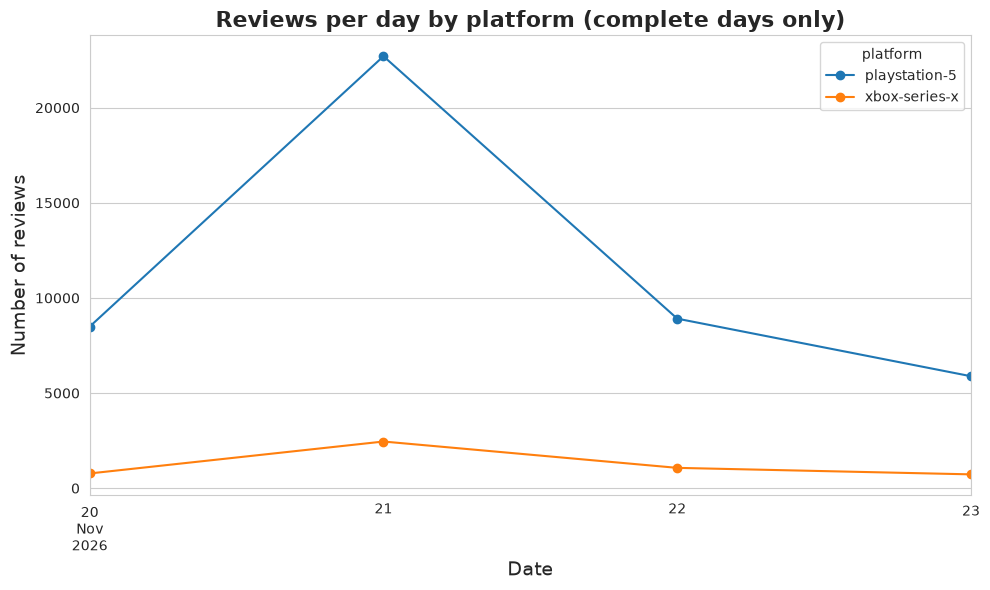

In [9]:
# Days with very few rows are scrape edges, not real activity: exclude them from trend charts.
MIN_DAILY_ROWS = 1000
partial_days = daily.index[daily['total'] < MIN_DAILY_ROWS]
print('Partial days excluded from trend charts:', [d.date().isoformat() for d in partial_days])

complete = daily.drop(index=partial_days).drop(columns='total')

fig, ax = plt.subplots(figsize=(10, 6))
complete.plot(marker='o', ax=ax)
ax.set_title('Reviews per day by platform (complete days only)', fontweight='bold', fontsize=16)
ax.set_xlabel('Date', fontsize=14)
ax.set_ylabel('Number of reviews', fontsize=14)
plt.tight_layout()
plt.show()

The data cover about 5 days around launch, and volume peaks on a single day. Conclusions apply to the launch window only: later reviews (after patches or DLC, or once review fatigue sets in) are not in this sample.

### 2.4 Platforms

In [10]:
platform_counts = df['platform'].value_counts()
pd.DataFrame({'reviews': platform_counts, 'share %': (platform_counts / len(df) * 100).round(1)})

,reviews,share %
platform,,
playstation-5,46317,90.1
xbox-series-x,5068,9.9


PS5 accounts for about 90% of reviews, so platform comparisons below use proportions within each platform instead of raw counts, which would mostly show group size.

### 2.5 Score distribution

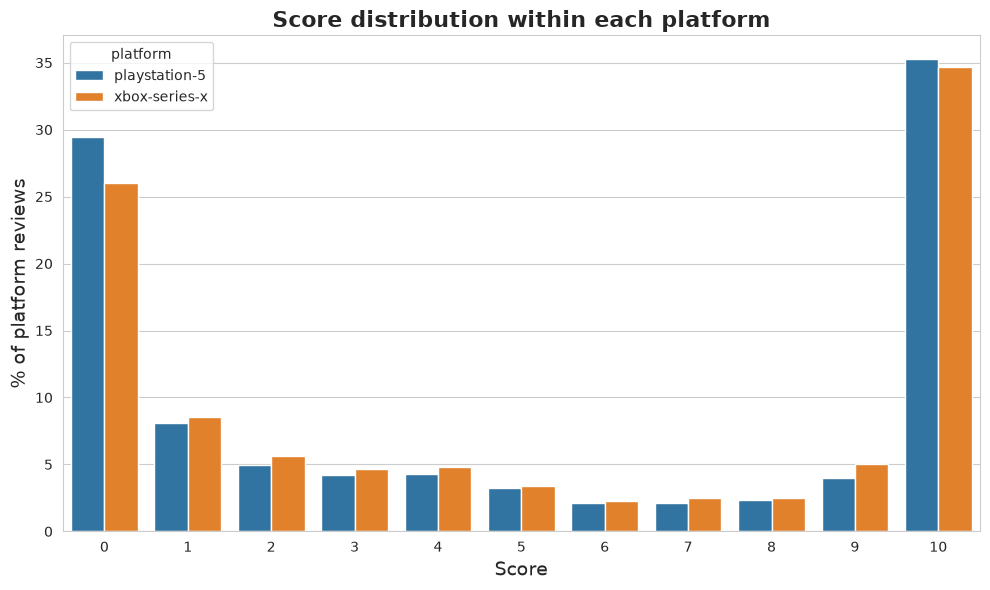

In [11]:
score_share = pd.crosstab(df['platform'], df['score'], normalize='index').mul(100)
plot_df = score_share.reset_index().melt(id_vars='platform', var_name='score', value_name='share')

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_df, x='score', y='share', hue='platform', ax=ax)
ax.set_title('Score distribution within each platform', fontweight='bold', fontsize=16)
ax.set_xlabel('Score', fontsize=14)
ax.set_ylabel('% of platform reviews', fontsize=14)
ax.legend(title='platform')
plt.tight_layout()
plt.show()

In [12]:
def polarization(s):
    return pd.Series({
        'n': len(s),
        'mean': s.mean(),
        'median': s.median(),
        '% score 0-1': (s <= 1).mean() * 100,
        '% score 2-8': s.between(2, 8).mean() * 100,
        '% score 9-10': (s >= 9).mean() * 100,
    })

score_stats = df.groupby('platform')['score'].apply(polarization).unstack()
score_stats.loc['all'] = polarization(df['score'])
score_stats.round(2)

,n,mean,median,% score 0-1,% score 2-8,% score 9-10
platform,,,,,,
playstation-5,46317.0,4.99,4.0,37.50,23.22,39.28
xbox-series-x,5068.0,5.13,5.0,34.57,25.71,39.72
all,51385.0,5.00,4.0,37.22,23.46,39.32


In [13]:
ps5 = df.loc[df['platform'] == 'playstation-5', 'score']
xbox = df.loc[df['platform'] == 'xbox-series-x', 'score']
u, p = stats.mannwhitneyu(ps5, xbox)
prob_superiority = u / (len(ps5) * len(xbox))  # P(PS5 > Xbox) + 0.5 * P(tie)
print(f'Mann-Whitney U p-value: {p:.2g} | P(PS5 score > Xbox score) = {prob_superiority:.3f} (0.5 = no difference)')

Mann-Whitney U p-value: 0.013 | P(PS5 score > Xbox score) = 0.490 (0.5 = no difference)


The distribution is U-shaped: 76% of reviews are 0 to 1 (37%) or 9 to 10 (39%), and only 23% fall in between. The mean (~5) describes almost nobody, so use the median, the share of each extreme, or the full distribution.

Xbox is a bit more positive (median 5 vs 4; 34.6% vs 37.5% of reviews at 0-1), but the difference is barely significant (p = 0.013) and the probability of superiority is 0.49. In practice the platforms behave alike. The Xbox sample has only ~5k rows.

### 2.6 Score over time

Scores are grouped into bands (0-1, 2-8, 9-10) because the mean hides what the two extremes do.

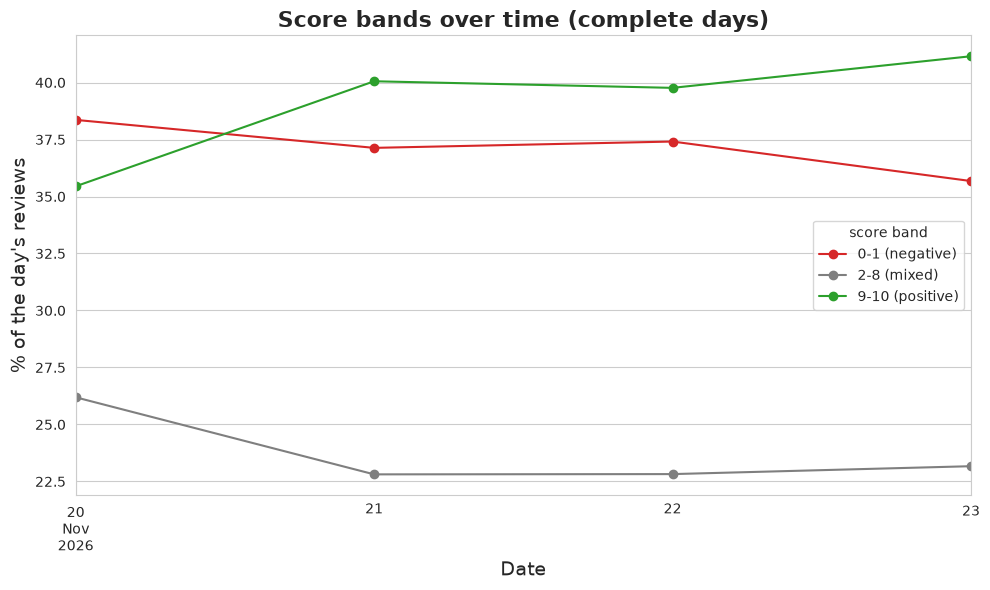

score_band,0-1 (negative),2-8 (mixed),9-10 (positive)
published_date,,,
2026-11-20,38.4,26.2,35.4
2026-11-21,37.1,22.8,40.1
2026-11-22,37.4,22.8,39.8
2026-11-23,35.7,23.2,41.2


In [14]:
BANDS = [-1, 1, 8, 10]
BAND_LABELS = ['0-1 (negative)', '2-8 (mixed)', '9-10 (positive)']
df['score_band'] = pd.cut(df['score'], bins=BANDS, labels=BAND_LABELS)

d = df[~df['published_date'].isin(partial_days)]
band_daily = pd.crosstab(d['published_date'], d['score_band'], normalize='index').mul(100)

fig, ax = plt.subplots(figsize=(10, 6))
band_daily.plot(marker='o', ax=ax, color=['tab:red', 'tab:gray', 'tab:green'])
ax.set_title('Score bands over time (complete days)', fontweight='bold', fontsize=16)
ax.set_xlabel('Date', fontsize=14)
ax.set_ylabel('% of the day\'s reviews', fontsize=14)
ax.legend(title='score band')
plt.tight_layout()
plt.show()
band_daily.round(1)

### 2.7 Review length and duplicated texts

Length is a cheap proxy for effort. Repeated texts point to copy-paste campaigns (review bombing or cheerleading), so we check which end of the score range they sit on.

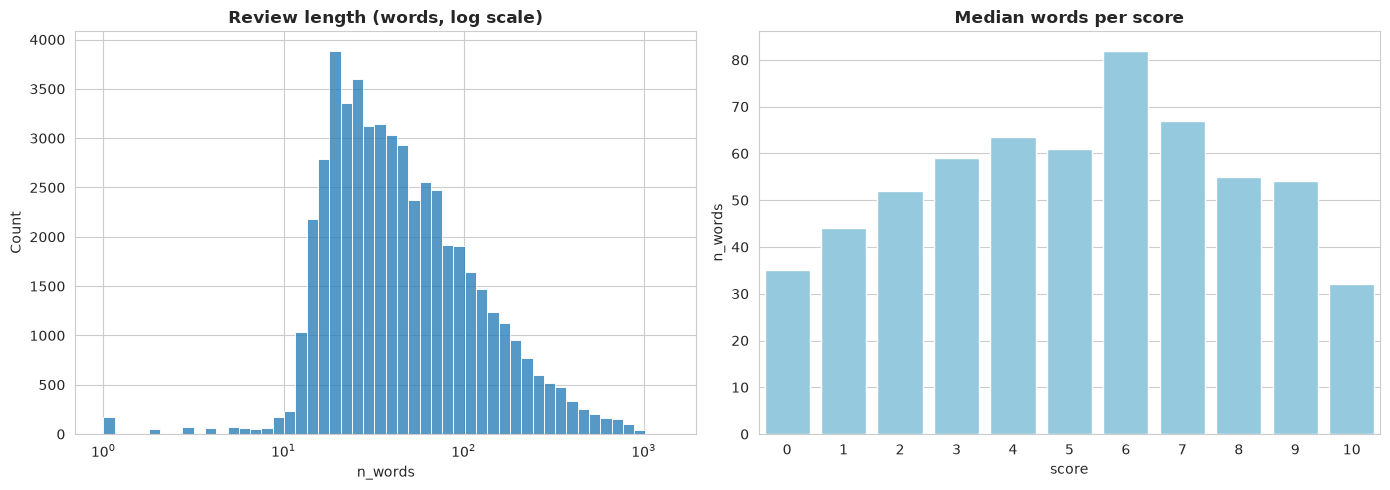

In [15]:
df['n_words'] = df['review_text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df, x='n_words', bins=50, log_scale=True, ax=axes[0])
axes[0].set_title('Review length (words, log scale)', fontweight='bold')
sns.barplot(data=df, x='score', y='n_words', estimator='median', errorbar=None, ax=axes[1], color='skyblue')
axes[1].set_title('Median words per score', fontweight='bold')
plt.tight_layout()
plt.show()

In [16]:
dup_by_band = df.groupby('score_band', observed=True)['dup_text'].mean().mul(100).round(1)
dup_by_band.rename('% rows with a repeated text')

score_band
0-1 (negative)     3.2
2-8 (mixed)        2.1
9-10 (positive)    2.0
Name: % rows with a repeated text, dtype: float64

Reviews are short (median 39 words). Length against score forms an inverted U: the extremes are the shortest (median 35 words at score 0, 32 at score 10), while scores 4 to 9 write 54 to 82. Strongly opinionated reviewers tend to post a quick verdict, and mixed reviewers explain themselves. Repeated texts are slightly more common among negatives (3.2%) than among mixed or positive reviews (2.0 to 2.1%), so copy-paste inflates the negative side by about one point.

### 2.8 Languages

Reviews are multilingual, and a topic model only makes sense within one language. `lingua` is restricted to 10 candidate languages and reads the first 200 characters. With a restricted set, a text in any other language gets forced into the nearest candidate, so we require a minimum relative distance between the top two candidates. Ambiguous texts become `unknown` instead of a guess.

In [17]:
from lingua import Language, LanguageDetectorBuilder
from tqdm import tqdm

detector = (
    LanguageDetectorBuilder.from_languages(
        Language.ENGLISH, Language.PORTUGUESE, Language.SPANISH,
        Language.ARABIC, Language.FRENCH, Language.GERMAN,
        Language.RUSSIAN, Language.CHINESE, Language.JAPANESE,
        Language.KOREAN,
    )
    .with_minimum_relative_distance(0.1)
    .build()
)


def detect_lang(text):
    """Return the language of a review text.

    Args:
        text (str): Review text. Non-strings and blank strings give `'unknown'`.

    Returns:
        str: Lowercase language name (for example `'english'`), or `'unknown'`
            when the detector cannot decide.
    """
    if not isinstance(text, str) or not text.strip():
        return 'unknown'
    lang = detector.detect_language_of(text[:200])
    return lang.name.lower() if lang else 'unknown'


tqdm.pandas(desc='Detecting languages')
df['language'] = df['review_text'].progress_apply(detect_lang)

Detecting languages:   0%|          | 0/51385 [00:00<?, ?it/s]

Detecting languages:   0%|          | 113/51385 [00:00<00:45, 1126.08it/s]

Detecting languages:   1%|          | 370/51385 [00:00<00:25, 1973.63it/s]

Detecting languages:   1%|▏         | 703/51385 [00:00<00:19, 2590.40it/s]

Detecting languages:   3%|▎         | 1314/51385 [00:00<00:12, 3977.74it/s]

Detecting languages:   4%|▎         | 1926/51385 [00:00<00:10, 4749.02it/s]

... (78 outputs left out)

Detecting languages:  97%|█████████▋| 49699/51385 [00:08<00:00, 6127.80it/s]

Detecting languages:  98%|█████████▊| 50334/51385 [00:08<00:00, 6192.87it/s]

Detecting languages:  99%|█████████▉| 50954/51385 [00:08<00:00, 6164.78it/s]

Detecting languages: 100%|██████████| 51385/51385 [00:08<00:00, 5737.87it/s]

In [18]:
lang_counts = df['language'].value_counts()
pd.DataFrame({'reviews': lang_counts, 'share %': (lang_counts / len(df) * 100).round(1)})

,reviews,share %
language,,
english,39901,77.7
spanish,6110,11.9
portuguese,3023,5.9
french,1053,2.0
german,505,1.0
russian,357,0.7
unknown,219,0.4
arabic,122,0.2
chinese,41,0.1


In [19]:
# What does the detector refuse to classify?
df.loc[df['language'] == 'unknown', ['platform', 'score', 'n_words', 'review_text']].sample(10, random_state=SEED)

,platform,score,n_words,review_text
41961,playstation-5,10,45,Perfect Perfect Perfect Perfect Perfect Perfect Perfect Perfect Perfect Perfect Perfect Perfect Perfect Perfect Perf...
29434,playstation-5,0,1,ג'קספגהג'קסאקפרגקסג'אהפג'ספגהאסוג'קספגהג'קסאקפרגקסג'אהפג'ספגהאסוג'קספגהג'קסאקפרגקסג'אהפג'ספגהאסו
51173,xbox-series-x,10,14,"Goty total, nintendo zzzzzzzzzzzzzzzzzzzzzzzzz y su remake todo mid, goty total el GTA 6"
51192,xbox-series-x,9,14,Çok iyi işte abi baya baya iyi yani 0 verenler maldır vallaaaaaaaaaaaaaaaaaa(75karakter olsun diye)
8354,playstation-5,0,14,"pessima fluidità, a volte scende anche a meno di 25fps, storia pessima, bug ovunque"
31875,playstation-5,0,16,NOT A REAL GTA. NO REAL PROTAGONIST. LUCIA IS NOT A LOVEABLE CHARACTER. DON'T BUY IT.
44349,playstation-5,0,7,The Legend of zelda es god ...
50177,playstation-5,7,2,Is ****.
25934,playstation-5,0,26,CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD CD
40054,playstation-5,0,114,"I prefer Zelda, GTA is ****. I prefer Zelda, GTA is ****. I prefer Zelda, GTA is ****. I prefer Zelda, GTA is ****. ..."


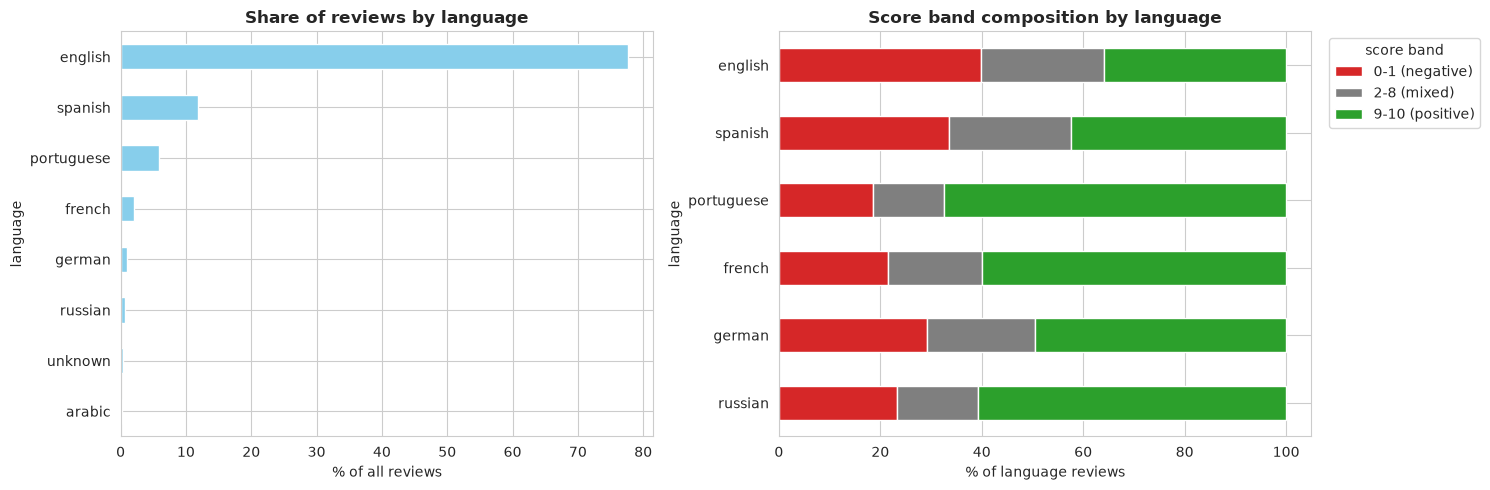

score_band,0-1 (negative),2-8 (mixed),9-10 (positive)
language,,,
english,39.8,24.4,35.8
french,21.5,18.5,60.0
german,29.1,21.4,49.5
portuguese,18.6,14.0,67.4
russian,23.2,16.0,60.8
spanish,33.5,24.1,42.4


In [20]:
top_langs = df['language'].value_counts().head(6).index.drop('unknown', errors='ignore')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
(lang_counts / len(df) * 100).head(8).sort_values().plot.barh(ax=axes[0], color='skyblue')
axes[0].set_title('Share of reviews by language', fontweight='bold')
axes[0].set_xlabel('% of all reviews')

band_by_lang = pd.crosstab(df.loc[df['language'].isin(top_langs), 'language'],
                           df.loc[df['language'].isin(top_langs), 'score_band'], normalize='index').mul(100)
band_by_lang.loc[top_langs[::-1]].plot.barh(stacked=True, ax=axes[1], color=['tab:red', 'tab:gray', 'tab:green'])
axes[1].set_title('Score band composition by language', fontweight='bold')
axes[1].set_xlabel('% of language reviews')
axes[1].legend(title='score band', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
band_by_lang.round(1)

English is the clear majority, so the topic model uses English only. Score mix differs a lot by language: English is the most negative (39.8% at 0-1), Portuguese the most positive (67.4% at 9-10, 18.6% negative), Spanish in between. An English-only topic model therefore describes English-speaking reviewers, not the whole audience, and every topic conclusion below carries that limit.

## 3. Data preparation

Each step shrinks the corpus, so we track the funnel:

1. Keep English reviews.
2. Drop repeated texts (keep the first). This removes cross-posted reviews and copy-paste campaigns that would otherwise form their own "topics".
3. Tokenize: lowercase, strip URLs, expand `n't`, letters only, collapse negations into `not_<word>` tokens, remove stopwords, lemmatize with POS tags.
4. Keep reviews with at least 10 tokens, which gives LDA enough words per document.

In [21]:
import re
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

for pkg in ['stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

In [22]:
stop_words = set(stopwords.words('english'))

# Keep negations: they carry sentiment
stop_words -= {'not', 'no', 'nor', 'never', 'none', "n't"}

# Review-specific stopwords: words so frequent they do not discriminate topics
custom_stopwords = {
    'game', 'games', 'play', 'played', 'playing', 'player', 'players',
    'like', 'really', 'would', 'could', 'get', 'got', 'one', 'also',
    'much', 'even', 'still', 'think', 'make', 'made', 'want', 'know',
    'see', 'going', 'time', 'thing', 'way', 'lot', 'good',
    'gta', 'rockstar',  # named entities
}
stop_words |= custom_stopwords

# "good" is a stopword on its own, but "not good" is a strong negative signal: keep it.
NEGATABLE_STOPWORDS = {'good'}
NEGATIONS = {'not', 'no', 'never', 'none', 'nor', 'cannot'}
PROTECTED_WORDS = {'woke', 'based', 'cringe', 'goated'}  # slang the lemmatizer would damage

lemmatizer = WordNetLemmatizer()

In [23]:
def get_wordnet_pos(treebank_tag):
    """Map a Penn Treebank POS tag to a WordNet POS tag.

    Args:
        treebank_tag (str): Tag returned by `nltk.pos_tag`, such as `'VBD'`.

    Returns:
        str: One of the WordNet constants (`ADJ`, `VERB`, `NOUN`, `ADV`).
            Unknown tags fall back to `NOUN`.
    """
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    if treebank_tag.startswith('V'):
        return wordnet.VERB
    if treebank_tag.startswith('N'):
        return wordnet.NOUN
    if treebank_tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN


def smart_lemmatize(word, tag):
    """Lemmatize a word, with a heuristic for -ed participles and slang protection.

    Args:
        word (str): Lowercase token.
        tag (str): Penn Treebank POS tag of the token.

    Returns:
        str: The lemma. Words in `PROTECTED_WORDS` are returned unchanged, and
            an -ed word tagged as an adjective is lemmatized as a verb when
            that changes it.
    """
    if word in PROTECTED_WORDS:
        return word
    wn_pos = get_wordnet_pos(tag)
    if word.endswith('ed') and wn_pos == wordnet.ADJ:
        verb_lemma = lemmatizer.lemmatize(word, wordnet.VERB)
        if verb_lemma != word:
            return verb_lemma
    return lemmatizer.lemmatize(word, wn_pos)


def preprocess(text):
    """Clean, tokenize, collapse negations and lemmatize a review text.

    Args:
        text (str): Raw review text.

    Returns:
        list[str]: Lemmatized tokens, with negations collapsed into `not_<word>`
            tokens. The list is empty for non-strings, blank strings, or texts
            that have no token left after stopword removal.
    """
    if not isinstance(text, str) or not text.strip():
        return []

    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r"n['\u2019]t\b", ' not', text)
    text = re.sub(r'cannot', 'can not', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()

    # Collapse negation + next word into one token, e.g. "not_good"
    collapsed, i = [], 0
    while i < len(tokens):
        if tokens[i] in NEGATIONS and i + 1 < len(tokens):
            collapsed.append(f'not_{tokens[i + 1]}')
            i += 2
        else:
            collapsed.append(tokens[i])
            i += 1

    # Drop "not_<stopword>" (e.g. "not_the") unless the negated word is informative
    collapsed = [
        t for t in collapsed
        if not (t.startswith('not_') and t[4:] in stop_words and t[4:] not in NEGATABLE_STOPWORDS)
    ]

    tokens = [t for t in collapsed if t not in stop_words and len(t) > 2]
    if not tokens:
        return []

    tagged = pos_tag(tokens)
    return [smart_lemmatize(w, t) for w, t in tagged]


# Sanity check on a hand-made sentence
print(preprocess("It's not good, I can't stand the 30 FPS and the bugs! Never again."))

['not_good', 'not_stand', 'fps', 'bug']


In [24]:
funnel = {'all reviews': len(df)}

df_en = df[df['language'] == 'english'].copy()
funnel['english'] = len(df_en)

df_en = df_en[~df_en['text_key'].duplicated(keep='first')].copy()
funnel['after dropping repeated texts'] = len(df_en)

tqdm.pandas(desc='Preprocessing with POS')
df_en['tokens'] = df_en['review_text'].progress_apply(preprocess)
df_en = df_en[df_en['tokens'].str.len() >= 10].copy()
funnel['with >= 10 tokens'] = len(df_en)

df_en['clean_text'] = df_en['tokens'].apply(' '.join)
pd.Series(funnel, name='rows').to_frame().assign(**{'% of all': lambda t: (t['rows'] / len(df) * 100).round(1)})

Preprocessing with POS:   0%|          | 0/39366 [00:00<?, ?it/s]

Preprocessing with POS:   0%|          | 112/39366 [00:00<00:35, 1119.87it/s]

Preprocessing with POS:   1%|          | 224/39366 [00:00<00:35, 1103.43it/s]

Preprocessing with POS:   1%|          | 352/39366 [00:00<00:32, 1182.28it/s]

Preprocessing with POS:   1%|          | 471/39366 [00:00<00:34, 1127.73it/s]

Preprocessing with POS:   2%|▏         | 629/39366 [00:00<00:30, 1284.39it/s]

... (271 outputs left out)

Preprocessing with POS:  99%|█████████▉| 39122/39366 [00:30<00:00, 1320.37it/s]

Preprocessing with POS: 100%|█████████▉| 39255/39366 [00:31<00:00, 1250.76it/s]

Preprocessing with POS: 100%|██████████| 39366/39366 [00:31<00:00, 1263.69it/s]

,rows,% of all
all reviews,51385,100.0
english,39901,77.7
after dropping repeated texts,39366,76.6
with >= 10 tokens,29586,57.6


In [25]:
# Inspect a few tokenized examples
for _, row in df_en.sample(3, random_state=SEED).iterrows():
    print(f"Original: {row['review_text'][:150]!r}")
    print(f"Tokens  : {row['tokens'][:20]}\n")

Original: 'GTA VI: Score 4/10, I expected GTA VI to be the defining game of the decade, the one that carries us until GTA VII. Instead, it feels like a huge miss'
Tokens  : ['score', 'expect', 'define', 'decade', 'carry', 'vii', 'instead', 'feel', 'huge', 'miss', 'mission', 'design', 'first', 'problem', 'many', 'mission', 'variation', 'goal', 'keep', 'lucia']

Original: 'How is it possible for a game that was 13 years in the making to be released with bugs and, on top of that, not even run at 60 fps on the PlayStation '
Tokens  : ['possible', 'year', 'make', 'release', 'bug', 'top', 'run', 'fps', 'playstation', 'disappoint']

Original: "The game is by far the most extensive and impressive ever released on console, it's RDR2 with a modern setting, and it's the best choice they could've"
Tokens  : ['far', 'extensive', 'impressive', 'ever', 'release', 'console', 'rdr', 'modern', 'set', 'best', 'choice', 'nothing']



The 10-token filter alone removes 25% of the English reviews. Extreme scores are the shortest reviews (see 2.7), so the modeled corpus leans toward longer, mid-score reviews: positive reviews (9-10) drop from 39.3% of all reviews to 33.3% of the modeled corpus, and mixed (2-8) rise from 23.5% to 28.0%. Short reactions ("GOTY", "trash") do not appear in the topics.

## 4. Modeling

LDA (`gensim`) on the lemmatized tokens, with two choices worth explaining:

- Vocabulary filtering with `filter_extremes` drops words that appear in fewer than 5 documents (typos, noise) or in more than 50% of documents (no discriminative power). Without it, LDA tends to produce a few giant generic topics and several near-empty ones.
- The number of topics comes from coherence (`c_v`, higher is better) and perplexity (lower is better), followed by reading the topics, since neither metric replaces that.

In [26]:
import gensim.corpora as corpora

texts = df_en['tokens'].tolist()
id2word = corpora.Dictionary(texts)
print('vocabulary before filtering:', len(id2word))
id2word.filter_extremes(no_below=5, no_above=0.5)
print('vocabulary after filtering: ', len(id2word))

corpus = [id2word.doc2bow(t) for t in texts]

# Drop documents left with fewer than 5 distinct in-vocabulary words
keep = np.array([len(bow) >= 5 for bow in corpus])
print('documents dropped after vocabulary filtering:', int((~keep).sum()))
df_en = df_en[keep].copy()
texts = [t for t, k in zip(texts, keep) if k]
corpus = [b for b, k in zip(corpus, keep) if k]
len(corpus)

vocabulary before filtering: 31690
vocabulary after filtering:  8696


documents dropped after vocabulary filtering: 155


29431

In [27]:
import time
from gensim.models import LdaModel, CoherenceModel

topic_range = [5, 8, 10, 12, 15, 20]
perplexities, coherence_scores = [], []

for num_topics in topic_range:
    start = time.time()
    model = LdaModel(corpus=corpus, id2word=id2word, num_topics=num_topics,
                     random_state=SEED, passes=5, alpha='auto')
    perplexities.append(np.exp2(-model.log_perplexity(corpus)))
    coherence_scores.append(
        CoherenceModel(model=model, texts=texts, dictionary=id2word, coherence='c_v').get_coherence()
    )
    print(f'Topics: {num_topics:2d} | Perplexity: {perplexities[-1]:8.2f} | '
          f'Coherence: {coherence_scores[-1]:.4f} | Time: {time.time() - start:.0f}s')

Topics:  5 | Perplexity:   160.44 | Coherence: 0.4329 | Time: 28s


Topics:  8 | Perplexity:   161.92 | Coherence: 0.4861 | Time: 28s


Topics: 10 | Perplexity:   174.22 | Coherence: 0.4821 | Time: 30s


Topics: 12 | Perplexity:   197.58 | Coherence: 0.4993 | Time: 30s


Topics: 15 | Perplexity:   213.25 | Coherence: 0.4943 | Time: 31s


Topics: 20 | Perplexity:   234.93 | Coherence: 0.4970 | Time: 33s


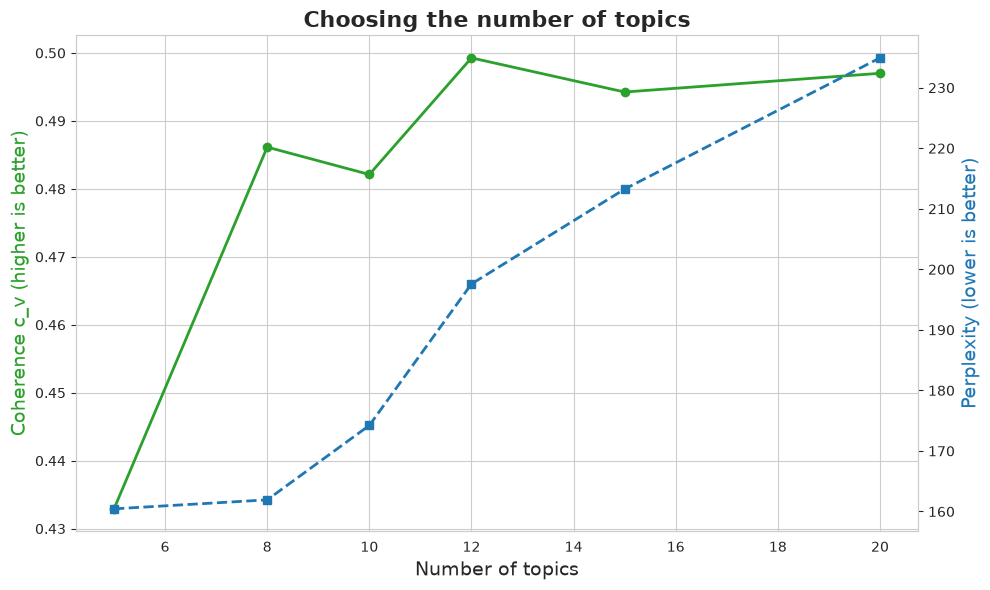

In [28]:
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(topic_range, coherence_scores, marker='o', color='tab:green', linewidth=2)
ax1.set_xlabel('Number of topics', fontsize=14)
ax1.set_ylabel('Coherence c_v (higher is better)', color='tab:green', fontsize=14)
ax2 = ax1.twinx()
ax2.plot(topic_range, perplexities, marker='s', color='tab:blue', linewidth=2, linestyle='--')
ax2.set_ylabel('Perplexity (lower is better)', color='tab:blue', fontsize=14)
ax2.grid(False)
plt.title('Choosing the number of topics', fontweight='bold', fontsize=16)
fig.tight_layout()
plt.show()

Coherence rises from 0.43 (5 topics) to 0.49 (8) and then stays between 0.48 and 0.50 up to 20 topics, with no clear peak. Perplexity increases steadily with the number of topics, so it does not favor a larger model either. With a flat coherence curve we pick 10 topics from the plateau, because each one has a readable theme (see below).

In [29]:
N_TOPICS = 10

lda_final = LdaModel(corpus=corpus, id2word=id2word, num_topics=N_TOPICS,
                     random_state=SEED, passes=10, alpha='auto')

pd.Series(
    {f'T{k:02d}': ', '.join(w for w, _ in lda_final.show_topic(k, topn=12)) for k in range(N_TOPICS)},
    name='top words',
).to_frame()

,top words
T00,"review, people, give, score, bomb, critic, fan, rating, best, say, game, ever"
T01,"world, detail, ever, open, best, every, incredible, experience, feel, masterpiece, level, alive"
T02,"woke, theft, auto, grand, woman, simulator, slop, franchise, men, feminist, garbage, cuck"
T03,"fps, year, bug, wait, release, console, hype, graphic, performance, frame, drop, gameplay"
T04,"character, lucia, jason, relationship, write, story, main, protagonist, force, personality, bore, bad"
T05,"story, feel, people, great, well, fun, thing, graphic, love, hour, rdr, say"
T06,"city, vice, san, andreas, rob, lucia, jason, non, bank, heist, michael, robbery"
T07,"car, dead, red, system, steal, drive, redemption, police, vehicle, shoot, mission, crime"
T08,"simulator, bore, life, bad, buy, money, chore, real, cant, dont, year, story"
T09,"feel, experience, world, freedom, theft, grand, auto, franchise, technical, impressive, gameplay, make"


In [30]:
import pyLDAvis
import pyLDAvis.gensim_models

pyLDAvis.enable_notebook()
pyLDAvis.gensim_models.prepare(lda_final, corpus, id2word, mds='tsne')

PreparedData(topic_coordinates=                x           y  topics  cluster       Freq
topic                                                    
5     -138.562729   62.172405       1        1  25.519742
9       46.802864   -4.274806       2        1  11.795082
3     -132.467834  -59.908554       3        1  11.613608
1       91.965347   87.201775       4        1   9.228314
8      -52.822704 -165.255524       5        1   9.061889
4      -25.529617  -70.342751       6        1   8.237564
0      -46.385979   25.184431       7        1   7.984420
7       68.099716 -124.093170       8        1   7.841828
2      143.564194  -33.232220       9        1   5.718700
6      -17.615273  123.402977      10        1   2.998854, topic_info=           Term          Freq         Total Category  logprob  loglift
67        world  10473.000000  10473.000000  Default  30.0000  30.0000
15          fps   7664.000000   7664.000000  Default  29.0000  29.0000
164      review   5095.000000   5095.000000  Default  28.0000  28.0000
100   character  10173.000000  10173.000000  Default  27.0000  27.0000
28        lucia   5707.000000   5707.000000  Default  26.0000  26.0000
...         ...           ...           ...      ...      ...      ...
2024   together    132.544877    609.969015  Topic10  -5.6081   1.9805
1025       walk    129.267154    520.021152  Topic10  -5.6332   2.1150
218     mission    173.038753   5365.444097  Topic10  -5.3415   0.0727
73         real    149.538706   3309.759976  Topic10  -5.4875   0.4099
337      around    135.905508   2511.174784  Topic10  -5.5831   0.5904

[749 rows x 6 columns], token_table=      Topic      Freq      Term
term                           
548       2  0.014928  absolute
548       3  0.075262  absolute
548       4  0.530569  absolute
548       5  0.095789  absolute
548       6  0.001244  absolute
...     ...       ...       ...
547       3  0.141283      zero
547       5  0.019443      zero
547       6  0.471808      zero
547       7  0.340894      zero
547       8  0.025924      zero

[1863 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[6, 10, 4, 2, 9, 5, 1, 8, 3, 7])

## 5. Evaluation

A topic model is useful only if its topics are interpretable, not degenerate in size, and assigned with reasonable confidence. The cells below check each.

In [31]:
assignments = [
    max(lda_final.get_document_topics(bow, minimum_probability=0.0), key=lambda x: x[1])
    for bow in corpus
]
df_en['dominant_topic'] = [t for t, _ in assignments]
df_en['topic_prob'] = [p for _, p in assignments]

# Labels are generated from the top words, so they can never go stale if the model changes
topic_label = {
    k: f"T{k:02d} " + '/'.join(w for w, _ in lda_final.show_topic(k, topn=3)) for k in range(N_TOPICS)
}
df_en['topic_label'] = df_en['dominant_topic'].map(topic_label)

print('Confidence of the dominant topic (share of the document explained by it):')
print(df_en['topic_prob'].describe().round(3).to_string())

Confidence of the dominant topic (share of the document explained by it):
count    29431.000
mean         0.439
std          0.134
min          0.158
25%          0.337
50%          0.417
75%          0.520
max          0.937


In [32]:
summary = df_en.groupby('topic_label').agg(
    reviews=('score', 'size'),
    mean_score=('score', 'mean'),
    median_score=('score', 'median'),
    pct_negative=('score', lambda s: (s <= 1).mean() * 100),
    pct_positive=('score', lambda s: (s >= 9).mean() * 100),
    mean_confidence=('topic_prob', 'mean'),
)
summary['share %'] = summary['reviews'] / summary['reviews'].sum() * 100
summary.sort_values('mean_score').round(2)

,reviews,mean_score,median_score,pct_negative,pct_positive,mean_confidence,share %
topic_label,,,,,,,
T02 woke/theft/auto,2106,0.99,0.0,80.77,2.56,0.42,7.16
T08 simulator/bore/life,3353,1.44,0.0,70.12,4.32,0.41,11.39
T04 character/lucia/jason,1648,1.94,1.0,56.92,3.16,0.38,5.60
T03 fps/year/bug,3730,2.01,1.0,59.52,4.93,0.43,12.67
T07 car/dead/red,812,3.31,2.0,44.46,16.63,0.35,2.76
T09 feel/experience/world,1658,3.55,2.0,42.52,17.91,0.44,5.63
T06 city/vice/san,139,4.86,3.0,39.57,39.57,0.43,0.47
T00 review/people/give,2445,5.68,9.0,37.06,51.49,0.43,8.31
T05 story/feel/people,10741,6.26,8.0,19.37,46.55,0.46,36.50


/home/miguel/git/reviews-gta6/.venv/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


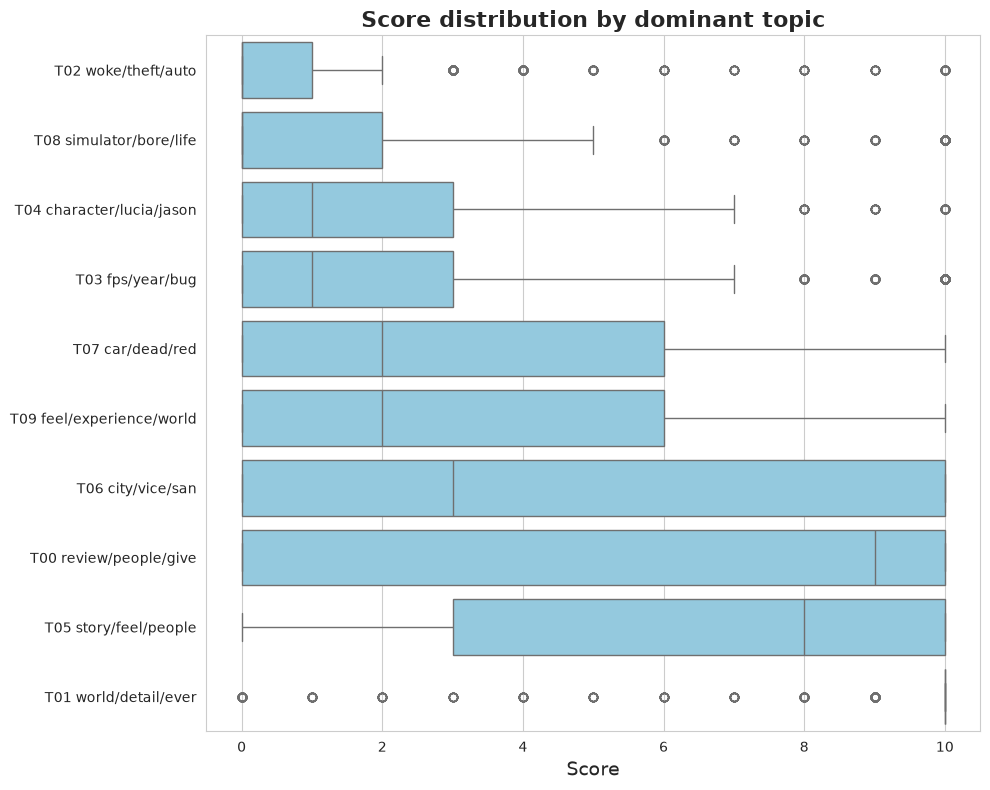

In [33]:
order = summary.sort_values('mean_score').index

fig, ax = plt.subplots(figsize=(10, 8))
sns.boxplot(data=df_en, y='topic_label', x='score', order=order, color='skyblue', ax=ax)
ax.set_title('Score distribution by dominant topic', fontweight='bold', fontsize=16)
ax.set_xlabel('Score', fontsize=14)
ax.set_ylabel('')
plt.tight_layout()
plt.show()

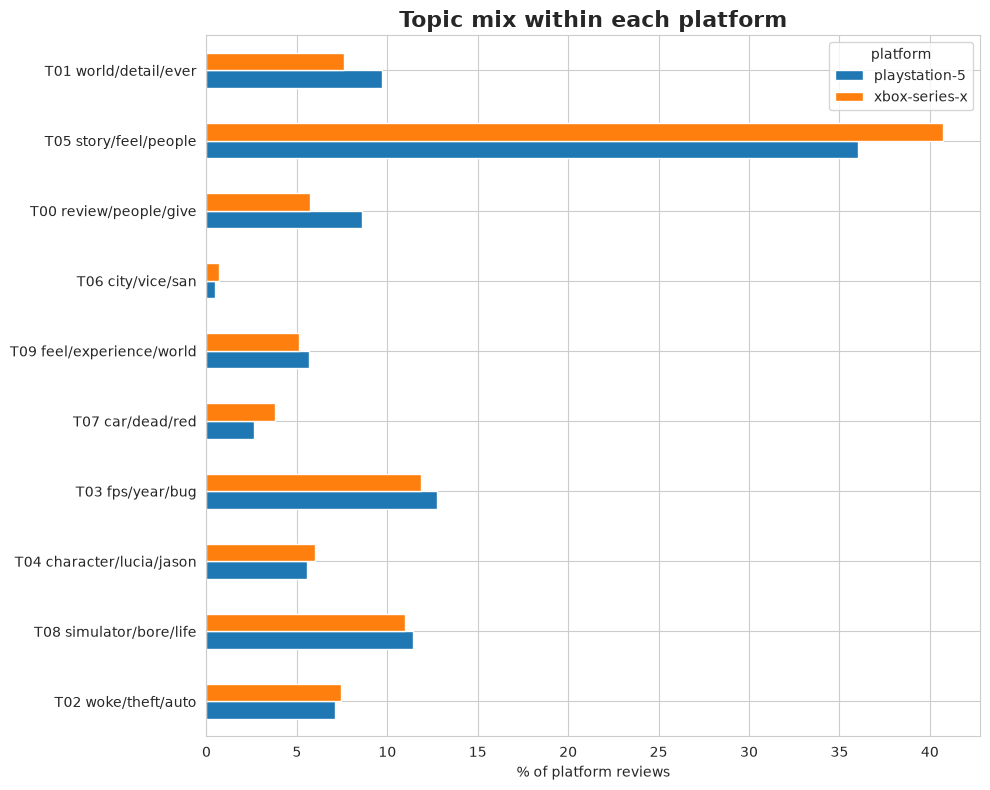

In [34]:
# Share of each platform's reviews that fall in each topic (normalized: PS5 is 9x bigger than Xbox)
topic_by_platform = (
    pd.crosstab(df_en['topic_label'], df_en['platform'], normalize='columns').mul(100).loc[order]
)
ax = topic_by_platform.plot.barh(figsize=(10, 8))
ax.set_title('Topic mix within each platform', fontweight='bold', fontsize=16)
ax.set_xlabel('% of platform reviews')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [35]:
# Most representative review of each topic (highest topic probability)
reps = df_en.loc[df_en.groupby('topic_label')['topic_prob'].idxmax(), ['topic_label', 'score', 'topic_prob', 'review_text']]
reps['review_text'] = reps['review_text'].str.slice(0, 350)
reps.sort_values('topic_label').reset_index(drop=True)

,topic_label,score,topic_prob,review_text
0,T00 review/people/give,10,0.841660,"Game is a 9/10 for me, leaving a 10/10 because of the incel losers review-bombing the game.\nAnd Metacritic, please,..."
1,T01 world/detail/ever,10,0.937406,10/10 – A Masterpiece. Rockstar Has Done It Again!GTA VI is hands down the best game I have ever played! The level o...
2,T02 woke/theft/auto,0,0.858355,"This is a boyfriend simulator where the boyfriend is a cuck, and the girlfriend is a **** piece of crap that abandon..."
3,T03 fps/year/bug,0,0.899751,"GTA 6 is an absolute disappointment after thirteen years of waiting. Rockstar somehow delivered a buggy, overpriced ..."
4,T04 character/lucia/jason,3,0.862237,"Lucia and Jason's story feels like derivative ""Bonnie and Clyde"" fanfiction. There's no real depth, no chemistry bet..."
5,T05 story/feel/people,9,0.914454,"I've made it to Chapter 3 so far and this game impressed me. Started off quite slower than older GTA games did, but ..."
6,T06 city/vice/san,0,0.886568,Dire osceno è veramente poco. Vedere per giunta quanti soldi hanno buttato nel cesso per fare sto schifo e pagare tu...
7,T07 car/dead/red,4,0.864938,They ruined GTA. They punish you for playing like the GTA games you remember. Instead of cutting loose and causing c...
8,T08 simulator/bore/life,0,0.844369,overrated ngl super boring story like why am i just cleaning houses. overrated ngl super boring story like why am i ...
9,T09 feel/experience/world,1,0.867555,"Visually, the game is beautiful. Its world is incredibly detailed, immersive, and impressive in its presentation. Ho..."


In [36]:
# Persist the modeled subset for follow-up work
OUT.mkdir(parents=True, exist_ok=True)
df_en.drop(columns=['tokens']).to_csv(OUT / 'reviews_en_topics.csv', index=False)

## 6. Findings, limitations and next steps

### Findings

1. Reception is polarized: 76% of reviews are 0-1 or 9-10, and the mean (5.0) hides that. Platforms behave alike, with Xbox slightly more positive.
2. The extremes are short verdicts (median 32 to 35 words), while mid-score reviews run 54 to 82 words.
3. Score depends heavily on the topic discussed (10 topics, English reviews):

   | Theme (topic) | Share | % negative (0-1) | % positive (9-10) |
   |---|---|---|---|
   | Open world, detail, "masterpiece" (T01) | 9.5% | 2.8% | 93.2% |
   | General story / fun / graphics praise (T05, large generic topic) | 36.5% | 19.4% | 46.6% |
   | "Woke", misogyny, culture war (T02) | 7.2% | 80.8% | 2.6% |
   | "Life simulator", boredom, chores (T08) | 11.4% | 70.1% | 4.3% |
   | Technical: 30 FPS, bugs, 13-year wait (T03) | 12.7% | 59.5% | 4.9% |
   | Characters Lucia and Jason, writing (T04) | 5.6% | 56.9% | 3.2% |
   | Review-bombing meta-discussion (T00) | 8.3% | 37.1% | 51.5% |

   Culture-war framing and "boring simulator" complaints are as negative as the FPS complaints, so negative reviews are not only about technical quality. The review-bombing topic (T00) leans positive: its most representative review gives a 10 to offset the bombing. Part of the 9-10 group is therefore a counter-reaction and not a pure quality signal.
4. Languages differ in sentiment: English is the most negative (39.8% at 0-1) and Portuguese the most positive (67.4% at 9-10).

### Limitations

- Only five launch days (two partial days dropped from trend charts), so nothing here shows how reception changes after patches or as review fatigue sets in.
- The topic model covers English only (78% of reviews) and reviews with at least 10 tokens (58% of all). Short extremes are underrepresented: 9-10 reviews fall from 39.3% to 33.3% of the corpus.
- Topic quality is moderate. Coherence plateaus near 0.5, one generic topic (T05) holds 36% of documents, T06 (Vice City and heist references) has only 139 reviews, and the dominant topic explains 44% of a review on average, so most reviews mix several topics. The labels are interpretations of the top words, not ground truth.
- Scores are user-reported. Copy-paste texts and cross-posting on both platforms are present (kept in section 2, removed before modeling), and reviews discuss bombing and counter-bombing, though the data cannot show who organizes it.
- The platform comparison is the only inferential test; everything else is descriptive.

### Next step proposal

Predict polarity (negative 0-1 vs positive 9-10) from the review text with TF-IDF and logistic regression. Evaluate with a temporal split (train on 20-21 Nov, test on 22-24 Nov) and compare across languages.

- The U-shaped score makes polarity close to a binary problem.
- The top coefficients show which words separate fans from critics, with a measured accuracy behind them, which LDA only suggests.
- Confidently misclassified reviews are worth reading, to see whether they are sarcasm, 10s given to offset bombing, or possible bots and campaigns.
- It reuses `data/processed/reviews_en_topics.csv` and extends to Spanish and Portuguese to test whether the same words matter.

Alternatives: an embeddings-based topic model (BERTopic with a multilingual sentence encoder) to cover all languages and the short reviews LDA drops, or a focused review-bombing analysis (templated texts, daily bursts, cross-posting profiles).